# Use the router inside a LangChain agent

The router you trained in `workshop_train_router.ipynb` becomes **LangChain middleware**: before the agent's first model
call it scores the user's question, then sends every model call to the cheap model (`gpt-oss-120b`) or the strong one
(`kimi-k3`), both on Fireworks serverless.

| Stage | What happens | Typical time |
|---|---|---|
| 1. Connect | Load `workshop_router.json`; reuse the router deployment, or redeploy if it's gone | instant (~4 min if redeploying) |
| 2. Replay | Both models answer 36 competition-math questions once; answers are cached in `runs/` | ~5-8 min the first time, instant after |
| 3. Pick a threshold | Score the 36 questions with the router, pick the threshold from real outcomes, check it on held-out halves | ~1 min |
| 4. Live agent | 6 of the questions through the LangChain agent, routed live; check the routing matches the replay | ~2-4 min |
| 5. Teardown | Delete the router deployment | instant |

**Why pick a threshold here?** The router learned "would a 10B model fail?". The cheap model in this agent is a 120B
model, so 0.5 is the wrong cut. As in the research runs, we choose it from what the two models actually do: both answer
every question, so for any threshold we can count the correct answers and the dollars it would have cost.

In [1]:
# Skip if you already ran this in the training notebook's environment.
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. Connect to the router

In [2]:
import ast
import json
import operator
import os
import re
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from datasets import load_dataset
from dotenv import load_dotenv
from fireworks import Fireworks
from tqdm.auto import tqdm

load_dotenv(next((p for p in (Path(".env"), Path("../.env")) if p.exists()), Path(".env")), override=True)
assert os.environ.get("FIREWORKS_API_KEY"), "put FIREWORKS_API_KEY in .env (see .env.example)"
fw = Fireworks()
if not os.environ.get("FIREWORKS_ACCOUNT_ID"):
    os.environ["FIREWORKS_ACCOUNT_ID"] = next(iter(fw.accounts.list())).name.split("/")[-1]
ACCOUNT_ID = os.environ["FIREWORKS_ACCOUNT_ID"].replace("accounts/", "")
API = os.environ.get("FIREWORKS_BASE_URL", "https://api.fireworks.ai").rstrip("/")

import training.renderer  # noqa: F401  (registers the cookbook renderers)
from training.utils.decision import decision_datums, option_token_ids
from training.utils.supervised import build_renderer_from_resolved_name
from training.utils.tokenizers import load_tokenizer

found = sorted(Path("runs").glob("workshop-*/workshop_router.json"), key=lambda p: p.stat().st_mtime)
assert found, "no trained router found; run workshop_train_router.ipynb first"
ROUTER_FILE = found[-1]
ROUTER = json.loads(ROUTER_FILE.read_text())
tok = load_tokenizer(ROUTER["tokenizer"])
renderer = build_renderer_from_resolved_name(tok, ROUTER["tokenizer"], ROUTER["renderer"])
COMPLETION_BUDGET_FLOOR = 10_000
ROUTER_MAX_TOKENS = 10_000   # one letter is expected; the cap never goes below the floor
assert ROUTER_MAX_TOKENS >= COMPLETION_BUDGET_FLOOR


def deploy(model, name):
    dep_id = f"{name}-{os.urandom(2).hex()}"
    shapes = [v.name for v in (fw.deployment_shape_versions.match_for_model(model).deployment_shape_versions or [])]
    assert shapes, f"no deployment shape matches {model}"
    spec = dict(base_model=model, deployment_id=dep_id, deployment_shape=shapes[0].split("/versions/")[0],
                min_replica_count=1, max_replica_count=1)
    fw.deployments.create(validate_only=True, **spec)
    dep_id = fw.deployments.create(**spec).name.split("/")[-1]
    bar = tqdm(range(240), desc=f"deploy {dep_id}")
    for _ in bar:
        state = str(fw.deployments.get(dep_id).state)
        bar.set_postfix(state=state.split(".")[-1])
        if state.endswith("READY"):
            return dep_id
        if any(s in state for s in ("FAILED", "DELETED", "DELETING")):
            raise RuntimeError(f"deployment {dep_id}: {state}")
        time.sleep(15)
    raise TimeoutError(dep_id)


try:
    state = str(fw.deployments.get(ROUTER["deployment_id"]).state)
except Exception as e:
    state = f"missing ({type(e).__name__})"
if not state.endswith("READY"):
    print(f"router deployment {ROUTER['deployment_id']} is {state}; redeploying {ROUTER['model']}")
    ROUTER["deployment_id"] = deploy(ROUTER["model"], f"workshop-router-{ROUTER['run'].split('-')[-1]}")
    ROUTER["endpoint"] = f"accounts/{ACCOUNT_ID}/deployments/{ROUTER['deployment_id']}"
    ROUTER_FILE.write_text(json.dumps(ROUTER, indent=2))
ENDPOINT, T = ROUTER["endpoint"], ROUTER["temperature"]
print(f"router {ROUTER['model']} on {ENDPOINT} | temperature {T:.2f} | trained on {ROUTER['train_examples']} rows")

/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/fireworks/training/sdk/_core/_compat.py:46: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1.typing import (


router accounts/pyroworks/models/workshop-router-dd20e9 on accounts/pyroworks/deployments/workshop-router-dd20e9-853e | temperature 2.28 | trained on 250 rows


In [3]:
_session = requests.Session()


def p_needs_large(text):
    """The router's calibrated probability that this prompt needs the large model."""
    row = {"state": text, "questions": {"route": {"type": "noul", "instructions": ROUTER["route_instructions"],
                                                 "criteria": ROUTER["route_criteria"], "label": True}}}
    d = decision_datums(row, renderer=renderer, renderer_name=ROUTER["renderer"], max_seq_len=8192)[0][1]
    id_a, id_b = option_token_ids(d)
    body = {"model": ENDPOINT, "prompt": d.model_input.to_ints(), "max_tokens": ROUTER_MAX_TOKENS,
            "temperature": 0.0, "logprobs": 5, "stop": ["<|im_end|>"]}
    for attempt in range(6):
        try:
            r = _session.post(f"{API}/inference/v1/completions", json=body, timeout=60,
                              headers={"Authorization": f"Bearer {os.environ['FIREWORKS_API_KEY']}"})
            if r.status_code in (429, 500, 502, 503, 504):
                raise requests.HTTPError(r.status_code)
            r.raise_for_status()
            break
        except (requests.HTTPError, requests.ConnectionError, requests.Timeout):
            if attempt == 5:
                raise
            time.sleep(min(2 ** attempt, 30))
    lp = r.json()["choices"][0]["logprobs"]
    top = lp["top_logprobs"][0] if "top_logprobs" in lp else {t["token"]: t["logprob"] for t in lp["content"][0]["top_logprobs"]}
    letter = {tok.decode([id_a]): 0, tok.decode([id_b]): 1}
    logits = np.array([-30.0, -30.0])
    if not any(t in letter for t in top):
        raise RuntimeError(f"router answered with neither letter: {top}")
    for token, logprob in top.items():
        if token in letter:
            logits[letter[token]] = max(logits[letter[token]], logprob)
    z = logits / T
    z -= z.max()
    return float(np.exp(z[0]) / np.exp(z).sum())


print("P(needs large | 'What is 7 * 8?') =", round(p_needs_large("What is 7 * 8?"), 3))

P(needs large | 'What is 7 * 8?') = 0.212


## 2. Replay: both models answer every question

The question mix follows the research runs' 144-question hard-math set, scaled down to 36:
[MATH](https://huggingface.co/datasets/EleutherAI/hendrycks_math) Level 5 (12),
[AIME 2022-24](https://huggingface.co/datasets/AI-MO/aimo-validation-aime) (12),
[AIME 2025](https://huggingface.co/datasets/MathArena/aime_2025) (8) and
[HMMT Feb 2025](https://huggingface.co/datasets/MathArena/hmmt_feb_2025) (4, numeric answers only).
`gpt-oss-120b` and `kimi-k3` each answer every question once through the same agent, with no router. The research runs
used 4 answers per model per question; one keeps the workshop short, so expect noisier numbers.

In [4]:
from langchain.agents import create_agent
from langchain.agents.middleware import AgentMiddleware, AgentState
from langchain.tools import tool
from langchain_core.messages import AIMessage, HumanMessage
from langchain_fireworks import ChatFireworks

CHEAP, STRONG = "accounts/fireworks/models/gpt-oss-120b", "accounts/fireworks/models/kimi-k3"
NAMES = {CHEAP: "gpt-oss-120b", STRONG: "kimi-k3"}
MAX_TOKENS = 32_000      # competition math reasons for a long time; a low cap returns empty answers
assert MAX_TOKENS >= COMPLETION_BUDGET_FLOOR
PRICES = {CHEAP: (0.15, 0.015, 0.60), STRONG: (3.00, 0.30, 15.00)}   # USD per 1M tokens: input, cached input, output


def chat(model):
    return ChatFireworks(model=model, temperature=0.6, max_tokens=MAX_TOKENS, timeout=1200, max_retries=2,
                         api_key=os.environ["FIREWORKS_API_KEY"], base_url=f"{API}/inference")


def message_cost(msg, priced_as=None):
    p_in, p_cached, p_out = PRICES[priced_as or msg.response_metadata["model_name"]]
    usage = msg.usage_metadata or {}
    cached = (usage.get("input_token_details") or {}).get("cache_read", 0) or 0
    return ((usage.get("input_tokens", 0) - cached) * p_in + cached * p_cached + usage.get("output_tokens", 0) * p_out) / 1e6


_OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
        ast.Pow: operator.pow, ast.Mod: operator.mod, ast.FloorDiv: operator.floordiv, ast.USub: operator.neg}


def _eval(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
        return _OPS[type(node.op)](_eval(node.left), _eval(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in _OPS:
        return _OPS[type(node.op)](_eval(node.operand))
    raise ValueError("unsupported expression")


@tool
def calculator(expression: str) -> str:
    """Evaluate an arithmetic expression, e.g. '(12 * 4) / 3 + 7'."""
    try:
        return str(_eval(ast.parse(expression, mode="eval").body))
    except Exception as e:
        return f"error: {e}"


SOLVER_PROMPT = ("Solve the math problem. Use the calculator tool for arithmetic. "
                 "End your answer with a final line of the form '#### <number>'.")


def extract_answer(text):
    m = re.findall(r"####\s*\$?(-?[\d,]*\.?\d+)", text)
    nums = m or re.findall(r"-?[\d,]*\.?\d+", text)
    try:
        return float(nums[-1].replace(",", "")) if nums else None
    except ValueError:
        return None


def is_correct(pred, gold):
    return pred is not None and abs(pred - gold) <= 1e-4 * max(1.0, abs(gold))


def last_boxed(s):
    i = s.rfind("\\boxed")
    if i < 0:
        return None
    j = s.find("{", i)
    depth, k = 0, j
    while k < len(s):
        depth += {"{": 1, "}": -1}.get(s[k], 0)
        if depth == 0:
            return s[j + 1:k]
        k += 1
    return None


def to_float(s):
    try:
        return float(str(s).replace(",", "").replace("$", "").replace("\\!", "").strip())
    except (TypeError, ValueError):
        return None


rng = np.random.default_rng(0)
sample = lambda rows, n: [rows[i] for i in rng.permutation(len(rows))[:n]]
math5 = [ex for ex in load_dataset("EleutherAI/hendrycks_math", "number_theory", split="test")
         if ex["level"] == "Level 5" and to_float(last_boxed(ex["solution"])) is not None]
aime_old = list(load_dataset("AI-MO/aimo-validation-aime", split="train"))
aime_2025 = list(load_dataset("MathArena/aime_2025", split="train"))
hmmt = [ex for ex in load_dataset("MathArena/hmmt_feb_2025", split="train") if to_float(ex["answer"]) is not None]
REPLAY = ([{"source": "MATH L5", "question": ex["problem"], "gold": to_float(last_boxed(ex["solution"]))} for ex in sample(math5, 12)]
          + [{"source": "AIME 2022-24", "question": ex["problem"], "gold": float(ex["answer"])} for ex in sample(aime_old, 12)]
          + [{"source": "AIME 2025", "question": ex["problem"], "gold": float(ex["answer"])} for ex in sample(aime_2025, 8)]
          + [{"source": "HMMT Feb 2025", "question": ex["problem"], "gold": to_float(ex["answer"])} for ex in sample(hmmt, 4)])
print(len(REPLAY), "questions:", dict(pd.Series([q["source"] for q in REPLAY]).value_counts()))

36 questions: {'MATH L5': np.int64(12), 'AIME 2022-24': np.int64(12), 'AIME 2025': np.int64(8), 'HMMT Feb 2025': np.int64(4)}


In [5]:
import hashlib

REPLAY_CACHE = Path("runs") / "replay_answers.jsonl"   # shared across router runs: the answers don't depend on the router
qid = lambda q: hashlib.sha1(q["question"].encode()).hexdigest()[:12]


def run_fixed(q, model):
    """One attempt with one model and no router. An empty or unparseable answer is a failed attempt, not an error."""
    t0 = time.time()
    agent = create_agent(model=chat(model), tools=[calculator], system_prompt=SOLVER_PROMPT)
    out = agent.invoke({"messages": [{"role": "user", "content": q["question"]}]}, {"recursion_limit": 50})
    msgs = [m for m in out["messages"] if isinstance(m, AIMessage)]
    return {"qid": qid(q), "model": model, "correct": is_correct(extract_answer(out["messages"][-1].text or ""), q["gold"]),
            "cost": sum(message_cost(m) for m in msgs), "seconds": time.time() - t0}


done = {}
if REPLAY_CACHE.exists():
    for line in REPLAY_CACHE.read_text().splitlines():
        r = json.loads(line)
        done[(r["qid"], r["model"])] = r
todo = [(q, m) for q in REPLAY for m in (CHEAP, STRONG) if (qid(q), m) not in done]
print(f"{len(done)} answers cached, {len(todo)} to run")
with ThreadPoolExecutor(8) as pool, REPLAY_CACHE.open("a") as sink:
    futures = [pool.submit(run_fixed, q, m) for q, m in todo]
    bar = tqdm(as_completed(futures), total=len(futures), desc="replay")
    for f in bar:
        r = f.result()
        done[(r["qid"], r["model"])] = r
        sink.write(json.dumps(r) + "\n"); sink.flush()   # an interrupted run resumes where it stopped
        bar.set_postfix(last=f"{NAMES[r['model']]} {'ok' if r['correct'] else 'wrong'}")

with ThreadPoolExecutor(8) as pool:
    scores = list(tqdm(pool.map(lambda q: p_needs_large(q["question"]), REPLAY), total=len(REPLAY), desc="router scores"))
REPLAY_DF = pd.DataFrame([{"source": q["source"], "question": q["question"][:70] + "…", "p": p,
                           "cheap_ok": done[(qid(q), CHEAP)]["correct"], "cheap_cost": done[(qid(q), CHEAP)]["cost"],
                           "strong_ok": done[(qid(q), STRONG)]["correct"], "strong_cost": done[(qid(q), STRONG)]["cost"]}
                          for q, p in zip(REPLAY, scores)])

by_source = REPLAY_DF.groupby("source", sort=False).agg(questions=("p", "size"), **{
    "gpt-oss-120b correct": ("cheap_ok", "mean"), "kimi-k3 correct": ("strong_ok", "mean"),
    "router P(needs large)": ("p", "median")})
display(by_source.style.format({"gpt-oss-120b correct": "{:.0%}", "kimi-k3 correct": "{:.0%}", "router P(needs large)": "{:.2f}"}))
disagree = (REPLAY_DF["cheap_ok"] != REPLAY_DF["strong_ok"]).sum()
print(f"the two models disagree on {disagree} of {len(REPLAY_DF)} questions; only those can be won or lost by routing")

0 answers cached, 72 to run


replay:   0%|          | 0/72 [00:00<?, ?it/s]

Retrying langchain_fireworks.chat_models._completion_with_retry.<locals>._call in 4 seconds as it raised InternalServerError: Error code: 504 - {'error': {'message': 'Gateway timeout', 'param': None, 'code': 'GATEWAY_TIMEOUT', 'type': 'error'}, 'request_id': 'chatcmpl-45b849cb26f44e52b3df479d086627ec'}.


router scores:   0%|          | 0/36 [00:00<?, ?it/s]

,questions,gpt-oss-120b correct,kimi-k3 correct,router P(needs large)
source,,,,
MATH L5,12,92%,100%,0.71
AIME 2022-24,12,75%,100%,0.81
AIME 2025,8,88%,100%,0.81
HMMT Feb 2025,4,50%,100%,0.85


the two models disagree on 7 of 36 questions; only those can be won or lost by routing


## 3. Pick a threshold from real outcomes

Any threshold sends questions scoring at or above it to `kimi-k3` and the rest to `gpt-oss-120b`. With both models'
answers saved, we can score every threshold on two numbers:

- **accuracy**: the share of questions the routed model got right.
- **cost per correct answer**: Fireworks' *cost per successful task*
  ([Fireworks](https://fireworks.ai/blog/agent-execution-tax), [Arize x Fireworks benchmark](https://github.com/Arize-ai/fireworks-cost-benchmark)):

$$\text{cost per correct answer} = \frac{\text{total \$ spent, wrong answers included}}{\text{number of correct answers}}$$

The research runs used two ways to pick the threshold:

| Setting | Rule | When to use it |
|---|---|---|
| **Accuracy setting** | the threshold with the most correct answers (ties: the cheaper one) | the default: as accurate as possible, and usually cheaper than always-kimi |
| **Money-saving setting** | the cheapest threshold whose accuracy matches always-kimi | when cost matters most; expect it to slip on unlucky splits |

The router's own scoring cost is not included: it runs on a dedicated deployment billed by the hour, not per token.

,threshold,sent to kimi-k3,accuracy,cost per correct answer (¢)
gpt-oss-120b only,inf,0%,81%,0.24
kimi-k3 only,0.000,100%,100%,7.89
"router, accuracy setting",0.760,69%,100%,7.19
"router, money-saving setting",0.760,69%,100%,7.19


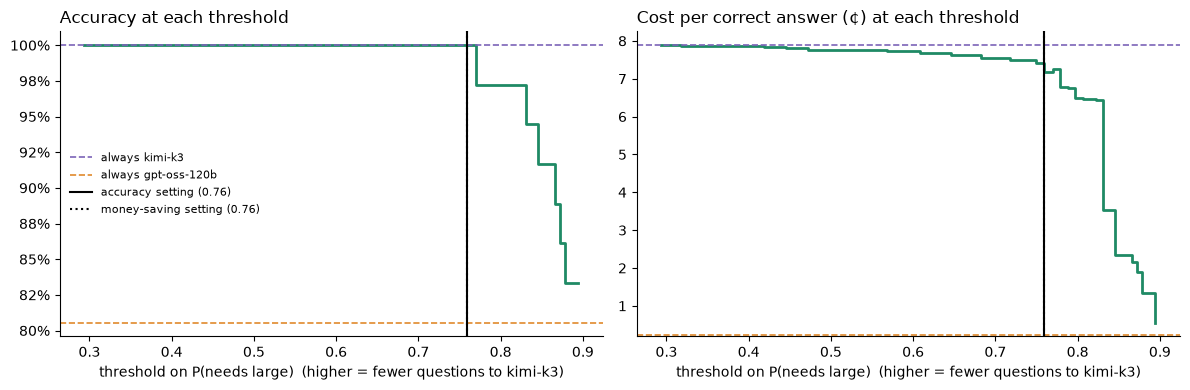

chosen on all 36 questions, so these numbers flatter the router; the held-out halves below are the honest ones


In [6]:
p = REPLAY_DF["p"].to_numpy()
ok = {CHEAP: REPLAY_DF["cheap_ok"].to_numpy(), STRONG: REPLAY_DF["strong_ok"].to_numpy()}
cost = {CHEAP: REPLAY_DF["cheap_cost"].to_numpy(), STRONG: REPLAY_DF["strong_cost"].to_numpy()}
ALL = np.arange(len(p))
CANDIDATES = np.r_[0.0, np.unique(p), np.inf]   # 0: everything to kimi; inf: everything to gpt-oss


def evaluate(t, idx):
    """Accuracy and cost per correct answer on questions idx if everything with p >= t goes to kimi-k3."""
    strong = p[idx] >= t
    correct = np.where(strong, ok[STRONG][idx], ok[CHEAP][idx])
    spend = np.where(strong, cost[STRONG][idx], cost[CHEAP][idx]).sum()
    return correct.mean(), spend / correct.sum() if correct.sum() else np.inf


def accuracy_setting(idx):
    return min(CANDIDATES, key=lambda t: (-evaluate(t, idx)[0], evaluate(t, idx)[1]))


def money_setting(idx):
    target = evaluate(0.0, idx)[0]
    return min((t for t in CANDIDATES if evaluate(t, idx)[0] >= target), key=lambda t: evaluate(t, idx)[1])


SETTINGS = {"accuracy setting": accuracy_setting(ALL), "money-saving setting": money_setting(ALL)}
THRESHOLD = float(SETTINGS["accuracy setting"])
rows = {"gpt-oss-120b only": np.inf, "kimi-k3 only": 0.0, **{f"router, {k}": v for k, v in SETTINGS.items()}}
display(pd.DataFrame({name: {"threshold": t, "sent to kimi-k3": (p >= t).mean(), "accuracy": evaluate(t, ALL)[0],
                             "cost per correct answer (¢)": 100 * evaluate(t, ALL)[1]} for name, t in rows.items()}).T
        .style.format({"threshold": "{:.3f}", "sent to kimi-k3": "{:.0%}", "accuracy": "{:.0%}", "cost per correct answer (¢)": "{:.2f}"}))

sweep = CANDIDATES[1:-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
ax1.step(sweep, [evaluate(t, ALL)[0] for t in sweep], where="post", color="#1F8A65", lw=2)
ax2.step(sweep, [100 * evaluate(t, ALL)[1] for t in sweep], where="post", color="#1F8A65", lw=2)
for ax, i, fmt in ((ax1, 0, lambda v: v), (ax2, 1, lambda v: 100 * v)):
    ax.axhline(fmt(evaluate(0.0, ALL)[i]), color="#7B64B8", ls="--", lw=1.2, label="always kimi-k3")
    ax.axhline(fmt(evaluate(np.inf, ALL)[i]), color="#E08A2C", ls="--", lw=1.2, label="always gpt-oss-120b")
    for (name, t), ls in zip(SETTINGS.items(), ("-", ":")):
        if np.isfinite(t) and t > 0:
            ax.axvline(t, color="k", ls=ls, lw=1.5, label=f"{name} ({t:.2f})")
    ax.set_xlabel("threshold on P(needs large)  (higher = fewer questions to kimi-k3)")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.set_title("Accuracy at each threshold", loc="left")
ax2.set_title("Cost per correct answer (¢) at each threshold", loc="left")
ax1.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print("chosen on all 36 questions, so these numbers flatter the router; the held-out halves below are the honest ones")

### The honest check: choose on one half, test on the other

Choosing a threshold and reporting results on the same questions flatters the router. So, as in the research runs, we
split the 36 questions in half at random, choose each setting on one half, freeze it, and report on the other half;
then repeat for 500 random splits. The always-one-model baselines are scored on the same held-out halves.

Each faint dot is one split; the big markers are medians. Best is top-left. With 18 test questions per split, a single
answer moves accuracy by about 6 points, so look at where the clouds sit, not at single dots.

held-out halves:   0%|          | 0/500 [00:00<?, ?it/s]

,median accuracy,median ¢ per correct,worst-10% accuracy
strategy,,,
gpt-oss-120b only,83.3%,0.24,72.2%
kimi-k3 only,100.0%,8.02,100.0%
"router, accuracy setting",100.0%,5.29,88.9%
"router, money-saving setting",100.0%,5.29,88.9%


router, accuracy setting and router, money-saving setting gave the same result on every split, so the chart draws them once


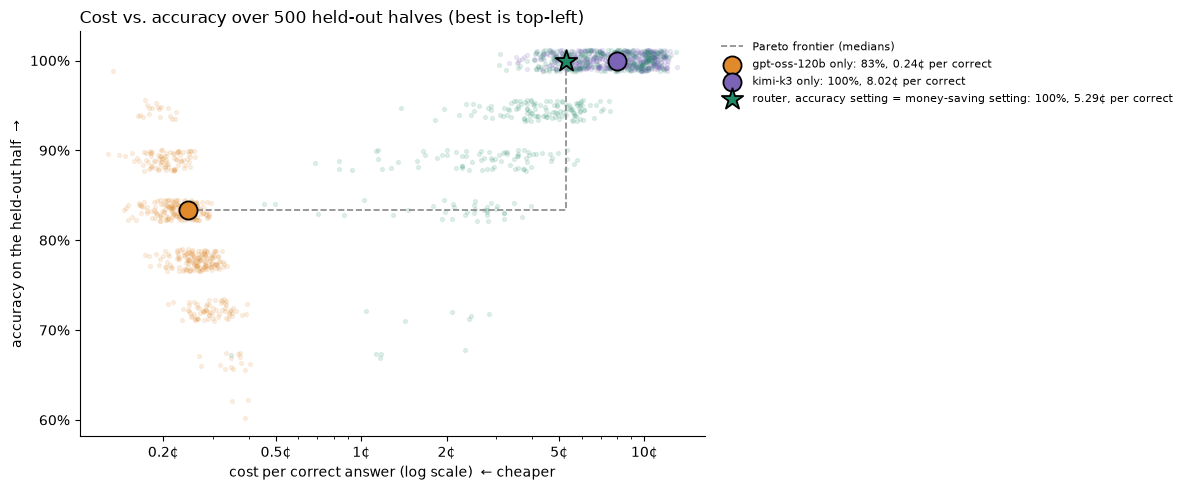

In [14]:
N_SPLITS = 500
split_rng = np.random.default_rng(0)
STRATS = {"gpt-oss-120b only": lambda fit: np.inf, "kimi-k3 only": lambda fit: 0.0,
          "router, accuracy setting": accuracy_setting, "router, money-saving setting": money_setting}
rows = []
for s in tqdm(range(N_SPLITS), desc="held-out halves"):
    perm = split_rng.permutation(len(p))
    fit, test = perm[: len(p) // 2], perm[len(p) // 2:]
    for name, choose in STRATS.items():
        acc, cpc = evaluate(choose(fit), test)
        rows.append({"split": s, "strategy": name, "accuracy": acc, "cents per correct": 100 * cpc})
SPLITS = pd.DataFrame(rows)
med = SPLITS.groupby("strategy", sort=False).agg(**{
    "median accuracy": ("accuracy", "median"), "median ¢ per correct": ("cents per correct", "median"),
    "worst-10% accuracy": ("accuracy", lambda a: a.quantile(0.1))})
display(med.style.format({"median accuracy": "{:.1%}", "median ¢ per correct": "{:.2f}", "worst-10% accuracy": "{:.1%}"}))

COLORS = {"gpt-oss-120b only": "#E08A2C", "kimi-k3 only": "#7B64B8",
          "router, accuracy setting": "#1F8A65", "router, money-saving setting": "#7FC8A9"}
# strategies with the same result on every split would sit exactly on top of each other: draw them once, names joined
groups = {}
for name in STRATS:
    groups.setdefault(SPLITS.loc[SPLITS["strategy"] == name, ["accuracy", "cents per correct"]].to_numpy().tobytes(), []).append(name)
for names in (g for g in groups.values() if len(g) > 1):
    joined = " = ".join([names[0]] + [n.removeprefix("router, ") for n in names[1:]])
    SPLITS = SPLITS[~SPLITS["strategy"].isin(names[1:])].replace({names[0]: joined})
    med = med.drop(names[1:]).rename(index={names[0]: joined})
    COLORS[joined] = COLORS[names[0]]
    print(f"{' and '.join(names)} gave the same result on every split, so the chart draws them once")
jit = np.random.default_rng(2)
fig, ax = plt.subplots(figsize=(12, 5))
for name, g in SPLITS.groupby("strategy", sort=False):
    g = g[np.isfinite(g["cents per correct"])]
    ax.scatter(g["cents per correct"], g["accuracy"] + jit.uniform(-0.012, 0.012, len(g)), s=8, alpha=0.12,
               color=COLORS[name], zorder=1)
pts = med.sort_values("median ¢ per correct")
frontier, best = [], -1
for name, r in pts.iterrows():
    if r["median accuracy"] > best:
        frontier.append(name)
        best = r["median accuracy"]
ax.step(pts.loc[frontier, "median ¢ per correct"], pts.loc[frontier, "median accuracy"], where="post", color="#888",
        ls="--", lw=1.2, zorder=2, label="Pareto frontier (medians)")
for name, r in med.iterrows():
    ax.scatter(r["median ¢ per correct"], r["median accuracy"], s=260 if "router" in name else 170,
               marker="*" if "router" in name else "o", color=COLORS[name], edgecolor="black", lw=1.3, zorder=3,
               label=f"{name}: {r['median accuracy']:.0%}, {r['median ¢ per correct']:.2f}¢ per correct")
ax.set_xscale("log")
ticks = [t for t in (0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50) if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]]
ax.set_xticks(ticks, [f"{t:g}¢" for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("cost per correct answer (log scale)  ← cheaper")
ax.set_ylabel("accuracy on the held-out half  →")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title(f"Cost vs. accuracy over {N_SPLITS} held-out halves (best is top-left)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

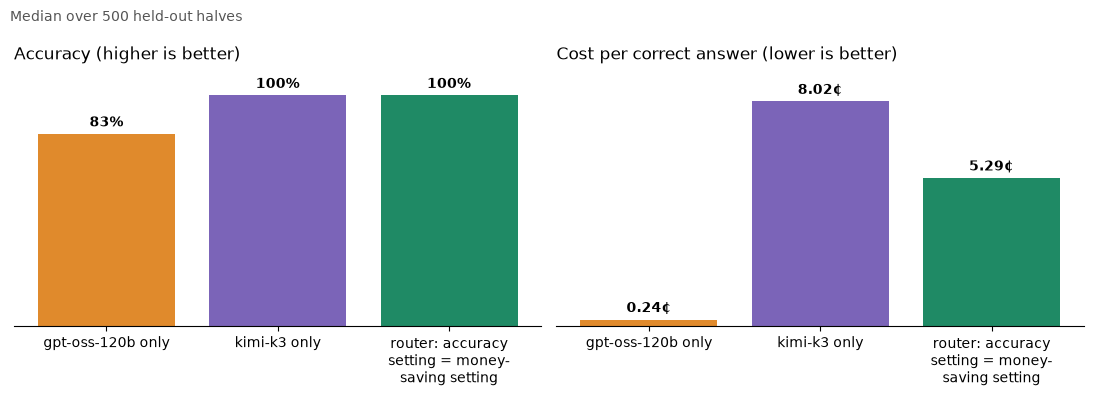

In [15]:
# the same held-out medians as the table above, as two simple bar charts
import textwrap

labels = [textwrap.fill(n.replace(",", ":"), 18) for n in med.index]
colors = [COLORS[n] for n in med.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, fmt, title in ((ax1, "median accuracy", lambda v: f"{v:.0%}", "Accuracy (higher is better)"),
                            (ax2, "median ¢ per correct", lambda v: f"{v:.2f}¢", "Cost per correct answer (lower is better)")):
    bars = ax.bar(labels, med[col], color=colors)
    ax.bar_label(bars, labels=[fmt(v) for v in med[col]], fontweight="bold", padding=3)
    ax.set_title(title, loc="left")
    ax.set_yticks([])
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
ax1.set_ylim(0, 1.12)
ax2.set_ylim(0, med["median ¢ per correct"].max() * 1.15)
fig.suptitle(f"Median over {N_SPLITS} held-out halves", x=0.01, ha="left", fontsize=10, color="#555")
plt.tight_layout(); plt.show()


## 4. The router as LangChain middleware

`before_agent` scores the user's question once; `wrap_model_call` swaps in the chosen model for every call the agent
makes. The threshold is the accuracy setting from step 3. Six replay questions run live, three the replay says go to
each model, and the table checks that the live agent routes each one the way the replay predicted. These questions were
part of the set that chose the threshold, so this checks the plumbing, not the threshold; the held-out halves above do that.

In [8]:
class RouterState(AgentState):
    p_needs_large: float
    routed_model: str


class RouterMiddleware(AgentMiddleware):
    """Score the latest user turn once with the router, then send every model call to the chosen model."""
    state_schema = RouterState

    def __init__(self, threshold):
        super().__init__()
        self.threshold = threshold
        self.models = {CHEAP: chat(CHEAP), STRONG: chat(STRONG)}

    def before_agent(self, state, runtime):
        task = next(m.content for m in reversed(state["messages"]) if isinstance(m, HumanMessage))
        p = p_needs_large(task)
        return {"p_needs_large": p, "routed_model": STRONG if p >= self.threshold else CHEAP}

    def wrap_model_call(self, request, handler):
        return handler(request.override(model=self.models[request.state["routed_model"]]))


router_mw = RouterMiddleware(THRESHOLD)
agent = create_agent(model=router_mw.models[CHEAP], tools=[calculator], system_prompt=SOLVER_PROMPT,
                     middleware=[router_mw])

live_rng = np.random.default_rng(1)
low, high = np.flatnonzero(p < THRESHOLD), np.flatnonzero(p >= THRESHOLD)
LIVE_IDX = list(live_rng.permutation(low)[:3]) + list(live_rng.permutation(high)[:3])


def run(i):
    q, t0 = REPLAY[i], time.time()
    out = agent.invoke({"messages": [{"role": "user", "content": q["question"]}]}, {"recursion_limit": 50})
    msgs = [m for m in out["messages"] if isinstance(m, AIMessage)]
    predicted = NAMES[STRONG if p[i] >= THRESHOLD else CHEAP]
    routed = NAMES[out["routed_model"]]
    return {"source": q["source"], "question": q["question"][:70] + "…", "P(needs large)": out["p_needs_large"],
            "replay predicted": predicted, "routed to": routed, "same as replay": predicted == routed,
            "correct": is_correct(extract_answer(out["messages"][-1].text or ""), q["gold"]),
            "cost $": sum(message_cost(m) for m in msgs), "seconds": time.time() - t0}


live = []
with ThreadPoolExecutor(6) as pool:
    futures = [pool.submit(run, i) for i in LIVE_IDX]
    for f in tqdm(as_completed(futures), total=len(futures), desc="agent runs"):
        r = f.result()
        live.append(r)
        print(f"[{time.strftime('%H:%M:%S')}] {r['source']:<14} P={r['P(needs large)']:.2f} -> {r['routed to']:<13} "
              f"{'correct' if r['correct'] else 'wrong  '} ${r['cost $']:.4f}  {r['seconds']:.0f}s", flush=True)
LIVE_DF = pd.DataFrame(live).sort_values("P(needs large)")
display(LIVE_DF.style.format({"P(needs large)": "{:.2f}", "cost $": "${:.4f}", "seconds": "{:.0f}"}))
print(f"{LIVE_DF['same as replay'].sum()}/{len(LIVE_DF)} routed as the replay predicted | "
      f"{LIVE_DF['correct'].sum()}/{len(LIVE_DF)} correct | ${LIVE_DF['cost $'].sum():.4f} total")

agent runs:   0%|          | 0/6 [00:00<?, ?it/s]

[09:09:17] AIME 2022-24   P=0.45 -> gpt-oss-120b  correct $0.0005  7s
[09:09:19] MATH L5        P=0.63 -> gpt-oss-120b  correct $0.0006  9s
[09:09:20] AIME 2025      P=0.68 -> gpt-oss-120b  correct $0.0008  9s
[09:09:38] MATH L5        P=0.78 -> kimi-k3       correct $0.0208  28s
[09:10:19] HMMT Feb 2025  P=0.76 -> kimi-k3       correct $0.0593  69s
[09:10:38] AIME 2022-24   P=0.83 -> kimi-k3       correct $0.0726  88s


,source,question,P(needs large),replay predicted,routed to,same as replay,correct,cost $,seconds
0,AIME 2022-24,Quadratic polynomials $P(x)$ and $Q(x)$ have leading coefficients $2$ …,0.45,gpt-oss-120b,gpt-oss-120b,True,True,$0.0005,7
1,MATH L5,Suppose that a $30$-digit integer $N$ is composed of thirteen $7$s and…,0.63,gpt-oss-120b,gpt-oss-120b,True,True,$0.0006,9
2,AIME 2025,"Find the number of ordered pairs $(x,y)$, where both $x$ and $y$ are i…",0.68,gpt-oss-120b,gpt-oss-120b,True,True,$0.0008,9
4,HMMT Feb 2025,Let $\mathcal{S}$ be the set of all nonconstant monic polynomials $P$ …,0.76,kimi-k3,kimi-k3,True,True,$0.0593,69
3,MATH L5,"If $a,b,c$ are positive integers less than $13$ such that \begin{align…",0.78,kimi-k3,kimi-k3,True,True,$0.0208,28
5,AIME 2022-24,"Let $a, b, x,$ and $y$ be real numbers with $a>4$ and $b>1$ such that\…",0.83,kimi-k3,kimi-k3,True,True,$0.0726,88


6/6 routed as the replay predicted | 6/6 correct | $0.1546 total


## 5. Teardown

Deletes the router deployment so it stops billing. The promoted model stays in your account; redeploy it any time.

In [9]:
fw.deployments.delete(ROUTER["deployment_id"], ignore_checks=True)
print("deleted", ROUTER["deployment_id"])

deleted workshop-router-dd20e9-853e
